# MLP regression

Train a small neural network (multi-layer perceptron) that predicts **SBP** and **DBP** from the 14 PPG features. Compare it with the naive baseline.

Run `preprocess.ipynb` and `ppg_feature_extraction.ipynb` first to create `data/ppg_features.csv`.

## 1. Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
FEATURE_COLUMNS = [
    "heart_rate_bpm", "beat_interval_std_ms", "pulse_height", "rise_time_s",
    "fall_time_s", "rise_fall_ratio", "pulse_width_s", "max_upslope",
    "ppg_std", "ppg_min", "ppg_max", "ppg_range", "ppg_skewness", "ppg_kurtosis",
]
TARGET_COLUMNS = ["sbp", "dbp"]

## 2. Load the feature table

In [2]:
df = pd.read_csv(Path("../data/ppg_features.csv"))
recordings = df[["file", "record_index"]].drop_duplicates().shape[0]
print(f"Loaded {len(df):,} windows from {recordings:,} recordings.")
df[FEATURE_COLUMNS + TARGET_COLUMNS].head()

Loaded 527,467 windows from 11,989 recordings.


,heart_rate_bpm,beat_interval_std_ms,pulse_height,rise_time_s,fall_time_s,rise_fall_ratio,pulse_width_s,max_upslope,ppg_std,ppg_min,ppg_max,ppg_range,ppg_skewness,ppg_kurtosis,sbp,dbp
0,121.841155,6.651835,1.817359,0.139000,0.352000,0.395105,0.172000,22.566971,0.603994,-1.015477,1.244404,2.259881,0.515651,-1.049128,121.841618,67.185065
1,124.309392,3.771236,1.841432,0.141000,0.341000,0.413552,0.173000,22.546256,0.603707,-0.828494,1.295174,2.123667,0.537671,-1.051481,124.747842,68.967875
2,123.966942,7.375636,1.856541,0.143111,0.342222,0.418236,0.175111,22.574495,0.640492,-0.888280,1.567517,2.455796,0.498770,-1.004504,125.846835,69.773803
3,123.175182,6.999118,1.845592,0.138000,0.350000,0.394474,0.170000,22.876972,0.652981,-1.261017,1.316331,2.577348,0.366763,-0.960664,122.354481,67.111799
4,124.309392,5.333333,1.879927,0.139000,0.343000,0.405369,0.172000,23.149714,0.606510,-0.843065,1.166942,2.010007,0.537381,-1.074263,125.578192,69.212096


## 3. Split by recording

- 80% of recordings for training, 20% for testing.
- All windows from one recording stay on the same side, so the model is tested on recordings it has never seen.
- The split is done separately within each file, with the same seed as the ridge and gradient boosting models, so the results can be compared directly.

In [3]:
train_index, test_index = [], []
for _, chunk in df.groupby("file"):
    groups = chunk[["file", "record_index"]].astype(str).agg("|".join, axis=1)
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
    train_pos, test_pos = next(splitter.split(chunk.index, groups=groups))
    train_index.extend(chunk.index[train_pos])
    test_index.extend(chunk.index[test_pos])

train_df = df.loc[train_index].reset_index(drop=True)
test_df = df.loc[test_index].reset_index(drop=True)

train_recordings = set(train_df[["file", "record_index"]].itertuples(index=False))
test_recordings = set(test_df[["file", "record_index"]].itertuples(index=False))
assert not train_recordings & test_recordings

X_train, y_train = train_df[FEATURE_COLUMNS], train_df[TARGET_COLUMNS]
X_test, y_test = test_df[FEATURE_COLUMNS], test_df[TARGET_COLUMNS]
print(f"Training windows: {len(train_df):,} ({len(train_recordings):,} recordings)")
print(f"Test windows: {len(test_df):,} ({len(test_recordings):,} recordings)")

Training windows: 420,509 (9,589 recordings)
Test windows: 106,958 (2,400 recordings)


## 4. Train the MLP

- The features are on very different scales, so they are standardized first. Neural networks train poorly otherwise.
- The SBP/DBP targets are standardized too, then converted back to mmHg for predictions.
- One network predicts both SBP and DBP.
- Two hidden layers of 64 and 32 neurons.
- Early stopping holds out 10% of the training rows and stops when the score on them stops improving.
- Training takes about 10 minutes on a laptop.

In [4]:
mlp = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(64, 32),
            early_stopping=True,
            validation_fraction=0.1,
            max_iter=200,
            random_state=RANDOM_STATE,
        ),
    ),
    transformer=StandardScaler(),
)
mlp.fit(X_train, y_train)

network = mlp.regressor_[-1]
print(f"Stopped after {network.n_iter_} epochs.")

Stopped after 91 epochs.


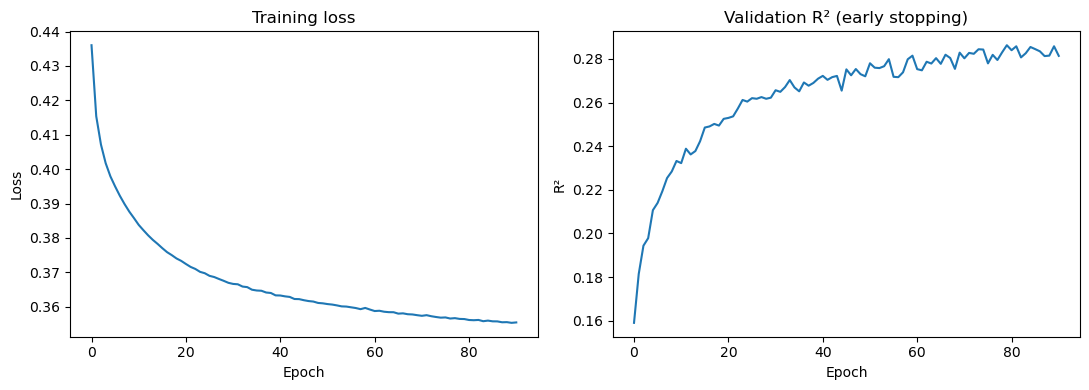

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(network.loss_curve_)
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Loss")
axes[1].plot(network.validation_scores_)
axes[1].set(title="Validation R² (early stopping)", xlabel="Epoch", ylabel="R²")
fig.tight_layout()
plt.show()

## 5. Evaluate on the test recordings

The naive baseline always predicts the training mean. The MLP needs a lower MAE and RMSE than the baseline to be useful.

In [6]:
mlp_predictions = mlp.predict(X_test)
baseline_predictions = np.tile(y_train.mean().to_numpy(), (len(X_test), 1))

rows = []
for model_name, predictions in [("naive_baseline", baseline_predictions), ("mlp", mlp_predictions)]:
    for i, target in enumerate(TARGET_COLUMNS):
        rows.append({
            "target": target,
            "model": model_name,
            "mae": mean_absolute_error(y_test[target], predictions[:, i]),
            "rmse": np.sqrt(mean_squared_error(y_test[target], predictions[:, i])),
            "r2": r2_score(y_test[target], predictions[:, i]),
        })

results = pd.DataFrame(rows).sort_values(["target", "model"], ascending=[False, False])
results.round(3)

,target,model,mae,rmse,r2
0,sbp,naive_baseline,18.545,22.809,-0.001
2,sbp,mlp,15.501,20.001,0.230
1,dbp,naive_baseline,9.151,11.985,-0.000
3,dbp,mlp,7.940,10.913,0.171


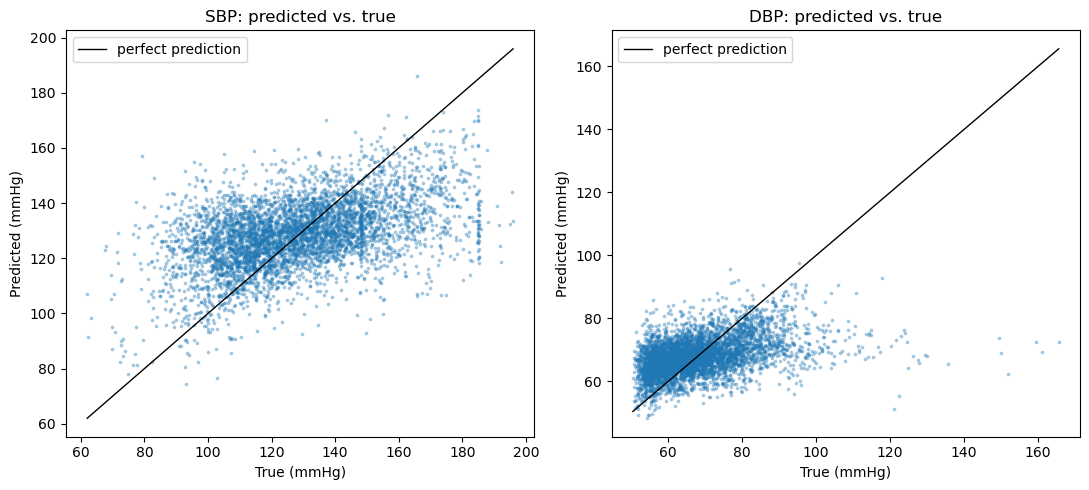

In [7]:
sample = np.random.default_rng(RANDOM_STATE).choice(len(y_test), size=5000, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (i, target) in zip(axes, enumerate(TARGET_COLUMNS)):
    true = y_test[target].to_numpy()[sample]
    ax.scatter(true, mlp_predictions[sample, i], s=3, alpha=0.3)
    limits = [true.min(), true.max()]
    ax.plot(limits, limits, color="black", linewidth=1, label="perfect prediction")
    ax.set(title=f"{target.upper()}: predicted vs. true", xlabel="True (mmHg)", ylabel="Predicted (mmHg)")
    ax.legend()
fig.tight_layout()
plt.show()

## 6. Findings

- The MLP beats the naive baseline for both targets:
  - **SBP:** MAE 15.50 vs. 18.55 mmHg, and R² 0.23.
  - **DBP:** MAE 7.94 vs. 9.15 mmHg, and R² 0.17.
- This is about the same as gradient boosting on the same split (SBP MAE 15.54, DBP MAE 7.94 in `modeling.ipynb`).
- The predicted-vs-true plots show predictions bunched toward the middle. The model rarely predicts very high or very low blood pressure, which matches the weak feature correlations found earlier.
- An error of about 15 mmHg for SBP is far from clinical accuracy (about 5 mmHg). Better features would likely help more than a bigger network.